# Chapter 15: Bellman Equations and Operators — Interactive Coding Project

Welcome to the companion coding project for **Chapter 15 (Bellman Equations and Operators)** of *Mathematics for AI and Machine Learning* (`math4ai.org`).

This notebook provides self-contained **NumPy** and **PyTorch** implementations and numerical verifications for all **11 Exercise Topics** in Chapter 15:
1. **Experiment 1 (Topics 1–5)**: MDP Policy Spaces, Bellman Contraction Operators ($T_\pi, T_*$), and Value Iteration vs. Policy Iteration.
2. **Experiment 2 (Topics 6 & 7)**: Discounted State Visitation Distributions $d_\pi(s)$ and Softmax Policy Gradients with Baseline Variance Reduction.
3. **Experiment 3 (Topics 8 & 9)**: Robbins–Monro Stochastic Approximation, Tabular Q-Learning, and Linear Function Approximation (The Deadly Triad).
4. **Experiment 4 (Topics 10 & 11)**: Off-Policy Importance Sampling Variance Explosion and Natural Policy Gradients / Trust-Region Fisher Ellipsoids.


In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (12, 4.8),
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
np.random.seed(42)
torch.manual_seed(42)
print("Environment initialized successfully.")


Environment initialized successfully.


---
## Experiment 1: MDP Policy Space, Bellman Contractions & Dynamic Programming (Topics 1–5)

### Mathematical Recap
- **Topic 1 (MDP Basics)**: A finite MDP with $N$ states and $M$ actions has $M^N$ deterministic policies and a convex set $(\Delta_M)^N$ of stochastic policies. For any $\pi \in \Pi$, the induced state transition matrix $P_\pi(s, s') = \sum_a \pi(a\mid s)P(s'\mid s,a)$ is row-stochastic ($P_\pi \mathbf{1} = \mathbf{1}$).
- **Topic 2 (Value Functions)**: $V_\pi(s) = \sum_a \pi(a\mid s)Q_\pi(s,a)$ and $Q_\pi(s,a) = R(s,a) + \gamma\sum_{s'}P(s'\mid s,a)V_\pi(s')$. Because $\rho(\gamma P_\pi) \le \gamma < 1$, $(I - \gamma P_\pi)$ is invertible via the Neumann series $\sum_{k=0}^\infty (\gamma P_\pi)^k$.
- **Topic 3 (Bellman Operators)**: Both $T_\pi$ and $T_*$ are $\gamma$-contractions in $\|\cdot\|_\infty$, satisfy componentwise dominance $T_*\mathbf{v} \ge T_\pi\mathbf{v}$, and are monotone ($\mathbf{u} \ge \mathbf{v} \implies T_\pi\mathbf{u} \ge T_\pi\mathbf{v}$).
- **Topics 4 & 5 (Optimal Policies & DP)**: Value Iteration converges geometrically ($\|\mathbf{v}_k - V_*\|_\infty \le \gamma^k\|\mathbf{v}_0 - V_*\|_\infty$), whereas Policy Iteration strictly improves $V_{\pi_k}$ at every step and terminates in at most $M^N$ steps.


Topic 1 | Deterministic policies count M^N = 729
Topic 1 | Max row-sum error of mixed policy: 1.11e-16
Topic 1 | Max row-sum error of P_pi:         2.22e-16
Topic 2 | ||V_pi - sum_a pi(a|s)Q_pi(s,a)||_inf: 8.88e-16
Topic 2 | ||V_pi_exact - Neumann(200)||_inf:     3.36e-09
Topic 3 | Max ||T_pi u - T_pi v|| / ||u-v|| = 0.7295 <= 0.9
Topic 3 | Max ||T_* u  - T_* v || / ||u-v|| = 0.7216 <= 0.9
Topic 3 | Dominance T_* u >= T_pi u holds everywhere: True
Topics 4 & 5 | Policy Iteration converged in 3 steps; ||V_PI - V_*||_inf = 1.78e-15


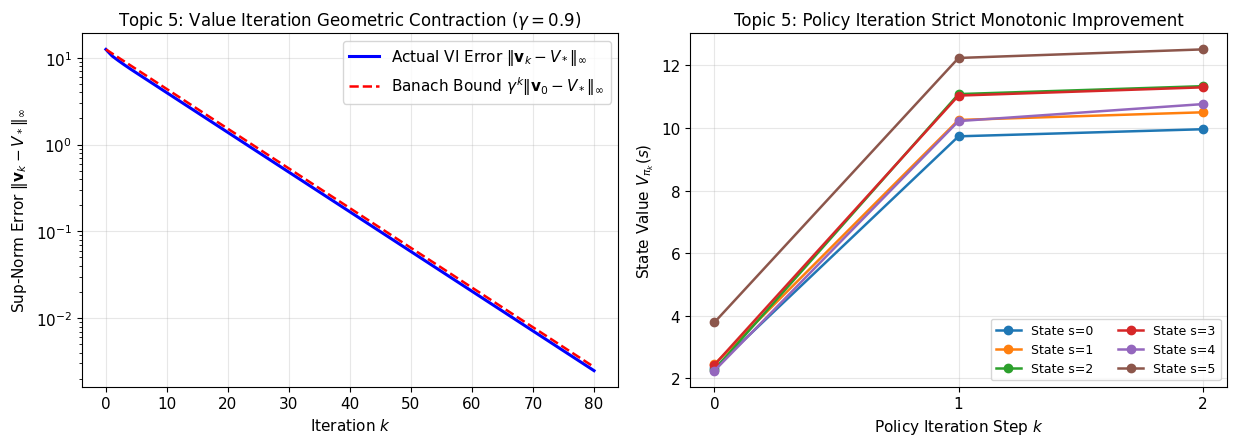

In [2]:
# Build a 6-state, 3-action finite MDP
N_states, M_actions = 6, 3
gamma = 0.9
rng = np.random.default_rng(42)

raw_P = rng.dirichlet(np.ones(N_states), size=(N_states, M_actions))
P = raw_P  # shape (S, A, S')
R = np.array([
    [0.0, 0.2, -0.1],
    [0.1, 0.5,  0.0],
    [-0.2, 0.4, 0.8],
    [0.3, 0.1,  1.2],
    [0.0, 0.9,  0.4],
    [1.5, 2.0,  0.5],
])

# Topic 1: Convexity of policy space & stochasticity of P_pi
pi_1 = rng.dirichlet(np.ones(M_actions), size=N_states)
pi_2 = rng.dirichlet(np.ones(M_actions), size=N_states)
lam = 0.35
pi_mix = lam * pi_1 + (1.0 - lam) * pi_2
P_pi = np.einsum("sa,san->sn", pi_mix, P)
r_pi = np.einsum("sa,sa->s", pi_mix, R)
print(f"Topic 1 | Deterministic policies count M^N = {M_actions**N_states}")
print(f"Topic 1 | Max row-sum error of mixed policy: {np.max(np.abs(pi_mix.sum(axis=1) - 1.0)):.2e}")
print(f"Topic 1 | Max row-sum error of P_pi:         {np.max(np.abs(P_pi.sum(axis=1) - 1.0)):.2e}")

# Topic 2: Exact linear solve vs. Neumann series expansion
v_pi_exact = np.linalg.solve(np.eye(N_states) - gamma * P_pi, r_pi)
Q_pi_exact = R + gamma * np.einsum("san,n->sa", P, v_pi_exact)
v_from_Q = np.einsum("sa,sa->s", pi_mix, Q_pi_exact)
neumann_v = np.zeros(N_states)
term = r_pi.copy()
for k in range(200):
    neumann_v += term
    term = gamma * (P_pi @ term)
print(f"Topic 2 | ||V_pi - sum_a pi(a|s)Q_pi(s,a)||_inf: {np.max(np.abs(v_pi_exact - v_from_Q)):.2e}")
print(f"Topic 2 | ||V_pi_exact - Neumann(200)||_inf:     {np.max(np.abs(v_pi_exact - neumann_v)):.2e}")

# Topic 3: Empirical check of gamma-contraction and dominance across 500 random vector pairs
max_ratio_pi, max_ratio_star = 0.0, 0.0
dominance_holds = True
for _ in range(500):
    u, v = rng.normal(0, 5, size=N_states), rng.normal(0, 5, size=N_states)
    dist_uv = np.max(np.abs(u - v))
    Tu_pi = r_pi + gamma * (P_pi @ u)
    Tv_pi = r_pi + gamma * (P_pi @ v)
    Tu_star = np.max(R + gamma * np.einsum("san,n->sa", P, u), axis=1)
    Tv_star = np.max(R + gamma * np.einsum("san,n->sa", P, v), axis=1)
    max_ratio_pi = max(max_ratio_pi, np.max(np.abs(Tu_pi - Tv_pi)) / dist_uv)
    max_ratio_star = max(max_ratio_star, np.max(np.abs(Tu_star - Tv_star)) / dist_uv)
    if np.any(Tu_star < Tu_pi - 1e-12):
        dominance_holds = False
print(f"Topic 3 | Max ||T_pi u - T_pi v|| / ||u-v|| = {max_ratio_pi:.4f} <= {gamma}")
print(f"Topic 3 | Max ||T_* u  - T_* v || / ||u-v|| = {max_ratio_star:.4f} <= {gamma}")
print(f"Topic 3 | Dominance T_* u >= T_pi u holds everywhere: {dominance_holds}")

# Topics 4 & 5: Value Iteration vs. Policy Iteration
V_star = np.zeros(N_states)
for _ in range(500):
    V_star = np.max(R + gamma * np.einsum("san,n->sa", P, V_star), axis=1)

V_vi = np.zeros(N_states)
vi_errors = [np.max(np.abs(V_vi - V_star))]
for k in range(1, 81):
    V_vi = np.max(R + gamma * np.einsum("san,n->sa", P, V_vi), axis=1)
    vi_errors.append(np.max(np.abs(V_vi - V_star)))

pi_curr = np.zeros(N_states, dtype=int)
pi_values = []
while True:
    P_c = P[np.arange(N_states), pi_curr]
    r_c = R[np.arange(N_states), pi_curr]
    V_c = np.linalg.solve(np.eye(N_states) - gamma * P_c, r_c)
    pi_values.append(V_c)
    Q_c = R + gamma * np.einsum("san,n->sa", P, V_c)
    pi_next = np.argmax(Q_c, axis=1)
    if np.array_equal(pi_next, pi_curr):
        break
    pi_curr = pi_next
pi_values = np.array(pi_values)
print(f"Topics 4 & 5 | Policy Iteration converged in {len(pi_values)} steps; ||V_PI - V_*||_inf = {np.max(np.abs(pi_values[-1] - V_star)):.2e}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
ks = np.arange(len(vi_errors))
axes[0].semilogy(ks, vi_errors, "b-", lw=2.2, label=r"Actual VI Error $\|\mathbf{v}_k - V_*\|_\infty$")
axes[0].semilogy(ks, (gamma ** ks) * vi_errors[0], "r--", lw=1.8, label=r"Banach Bound $\gamma^k \|\mathbf{v}_0 - V_*\|_\infty$")
axes[0].set_title(r"Topic 5: Value Iteration Geometric Contraction ($\gamma = 0.9$)")
axes[0].set_xlabel("Iteration $k$")
axes[0].set_ylabel(r"Sup-Norm Error $\|\mathbf{v}_k - V_*\|_\infty$")
axes[0].legend()

for s in range(N_states):
    axes[1].plot(np.arange(len(pi_values)), pi_values[:, s], marker="o", lw=1.8, label=f"State s={s}")
axes[1].set_title("Topic 5: Policy Iteration Strict Monotonic Improvement")
axes[1].set_xlabel("Policy Iteration Step $k$")
axes[1].set_ylabel(r"State Value $V_{\pi_k}(s)$")
axes[1].set_xticks(np.arange(len(pi_values)))
axes[1].legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()


---
## Experiment 2: State Visitation Distributions & Policy Gradient with Baselines (Topics 6 & 7)

### Mathematical Recap
- **Topic 6 (State Distributions)**: Under policy $\pi$, state distributions evolve via the linear system $\boldsymbol\mu_{t+1}^\top = \boldsymbol\mu_t^\top P_\pi$. For an ergodic Markov chain, $\boldsymbol\mu_t$ converges to the unique stationary distribution $\boldsymbol\mu_*^\top P_\pi = \boldsymbol\mu_*^\top$. The discounted state visitation distribution
  $$d_\pi(s) = (1-\gamma)\sum_{t=0}^\infty \gamma^t \mu_t(s) = \big[(1-\gamma)\boldsymbol\mu_0^\top (I - \gamma P_\pi)^{-1}\big]_s$$
  is a valid probability distribution ($\sum_s d_\pi(s) = 1$).
- **Topic 7 (Policy Gradient & Baselines)**: For a softmax policy $\pi_\theta(a\mid s) = \frac{e^{\theta_{sa}}}{\sum_{a'}e^{\theta_{sa'}}}$, the score function is $\frac{\partial\log\pi_\theta(a\mid s)}{\partial\theta_{sa'}} = \mathbb{I}(a=a') - \pi_\theta(a'\mid s)$. Subtracting any state-only baseline $b(s)$ leaves the expected gradient unchanged because $\mathbb{E}_{a\sim\pi_\theta}[\nabla_\theta\log\pi_\theta(a\mid s)b(s)] = 0$, while substantially reducing Monte Carlo gradient variance.


Topic 6 | Stationary residual ||mu_*^T P_pi - mu_*^T||_1: 3.05e-16
Topic 6 | Sum of discounted visitation d_pi(s):           1.000000
Topic 6 | ||d_pi_exact - d_pi_series(40)||_1:             1.48e-02
Topic 7 | Variance at B=1000 without baseline: 20.2040 vs with V(s) baseline: 0.0112


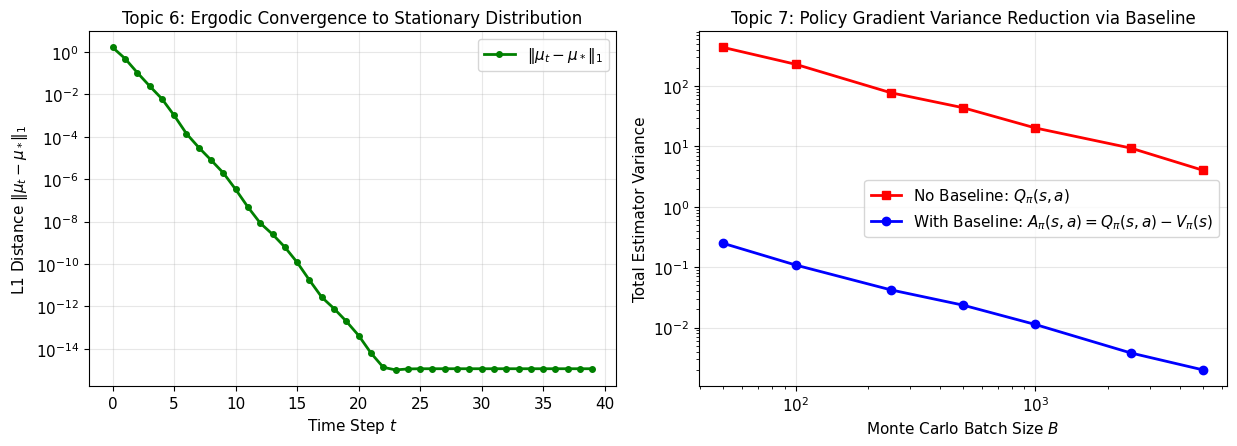

In [3]:
# Topic 6: Linear state distribution evolution, stationary distribution, and d_pi(s)
mu_0 = np.zeros(N_states)
mu_0[0] = 1.0  # start in state 0
T_steps = 40
mu_hist = np.zeros((T_steps, N_states))
mu_curr = mu_0.copy()
for t in range(T_steps):
    mu_hist[t] = mu_curr
    mu_curr = mu_curr @ P_pi

# Stationary distribution via left eigenvector of P_pi for eigenvalue 1
eigvals, eigvecs = np.linalg.eig(P_pi.T)
idx_one = np.argmin(np.abs(eigvals - 1.0))
mu_star = np.real(eigvecs[:, idx_one])
mu_star = mu_star / np.sum(mu_star)

# Discounted visitation measure d_pi: closed-form vs truncated series
d_pi_exact = (1.0 - gamma) * (mu_0 @ np.linalg.inv(np.eye(N_states) - gamma * P_pi))
d_pi_series = (1.0 - gamma) * np.sum((gamma ** np.arange(T_steps))[:, None] * mu_hist, axis=0)
print(f"Topic 6 | Stationary residual ||mu_*^T P_pi - mu_*^T||_1: {np.sum(np.abs(mu_star @ P_pi - mu_star)):.2e}")
print(f"Topic 6 | Sum of discounted visitation d_pi(s):           {np.sum(d_pi_exact):.6f}")
print(f"Topic 6 | ||d_pi_exact - d_pi_series(40)||_1:             {np.sum(np.abs(d_pi_exact - d_pi_series)):.2e}")

# Topic 7: Softmax policy gradient & baseline variance reduction
theta_logits = rng.normal(0, 0.6, size=(N_states, M_actions))
exp_logits = np.exp(theta_logits - np.max(theta_logits, axis=1, keepdims=True))
pi_soft = exp_logits / np.sum(exp_logits, axis=1, keepdims=True)
P_soft = np.einsum("sa,san->sn", pi_soft, P)
r_soft = np.einsum("sa,sa->s", pi_soft, R)
V_soft = np.linalg.solve(np.eye(N_states) - gamma * P_soft, r_soft) + 15.0  # shift reward baseline to highlight variance
Q_soft = (R + 1.5) + gamma * np.einsum("san,n->sa", P, V_soft)
d_soft = (1.0 - gamma) * (mu_0 @ np.linalg.inv(np.eye(N_states) - gamma * P_soft))

# Analytical policy gradient: (1/(1-gamma)) * sum_s d(s) sum_a pi(a|s) (I(a=a') - pi(a'|s)) Q(s,a)
adv_soft = Q_soft - V_soft[:, None]
grad_analytical = (1.0 / (1.0 - gamma)) * (d_soft[:, None] * pi_soft * adv_soft)

# Monte Carlo single-step gradient estimates across sample sizes
batch_sizes = [50, 100, 250, 500, 1000, 2500, 5000]
var_no_base, var_with_base = [], []
for B in batch_sizes:
    s_samples = rng.choice(N_states, size=(200, B), p=d_soft)
    u_rand = rng.random(size=(200, B, 1))
    cdf = np.cumsum(pi_soft[s_samples], axis=-1)
    a_samples = np.argmax(u_rand <= cdf, axis=-1)
    one_hot = np.eye(M_actions)[a_samples]
    score = one_hot - pi_soft[s_samples]  # (200, B, M)
    q_val = Q_soft[s_samples, a_samples][..., None]
    v_val = V_soft[s_samples][..., None]
    est_raw = (1.0 / (1.0 - gamma)) * np.mean(score * q_val, axis=1)
    est_base = (1.0 / (1.0 - gamma)) * np.mean(score * (q_val - v_val), axis=1)
    var_no_base.append(np.sum(np.var(est_raw, axis=0)))
    var_with_base.append(np.sum(np.var(est_base, axis=0)))

print(f"Topic 7 | Variance at B=1000 without baseline: {var_no_base[4]:.4f} vs with V(s) baseline: {var_with_base[4]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
t_grid = np.arange(T_steps)
tv_dist = np.sum(np.abs(mu_hist - mu_star[None, :]), axis=1)
axes[0].semilogy(t_grid, tv_dist, "g-o", markersize=4, lw=2, label=r"$\|\mu_t - \mu_*\|_1$")
axes[0].set_title("Topic 6: Ergodic Convergence to Stationary Distribution")
axes[0].set_xlabel("Time Step $t$")
axes[0].set_ylabel(r"L1 Distance $\|\mu_t - \mu_*\|_1$")
axes[0].legend()

axes[1].loglog(batch_sizes, var_no_base, "r-s", lw=2, label=r"No Baseline: $Q_\pi(s,a)$")
axes[1].loglog(batch_sizes, var_with_base, "b-o", lw=2, label=r"With Baseline: $A_\pi(s,a) = Q_\pi(s,a) - V_\pi(s)$")
axes[1].set_title("Topic 7: Policy Gradient Variance Reduction via Baseline")
axes[1].set_xlabel("Monte Carlo Batch Size $B$")
axes[1].set_ylabel("Total Estimator Variance")
axes[1].legend()
plt.tight_layout()
plt.show()


---
## Experiment 3: Stochastic Approximation, Tabular Q-Learning & The Deadly Triad (Topics 8 & 9)

### Mathematical Recap
- **Topic 8 (Stochastic Approximation & Q-Learning)**: Under Robbins–Monro step sizes $\sum_n \alpha_n = \infty$ and $\sum_n \alpha_n^2 < \infty$ (such as $\alpha_n = 1/n$), stochastic approximation $x_{n+1} = x_n + \alpha_n(-x_n + \xi_n)$ converges to $0$, and tabular Q-learning converges to the Bellman optimality fixed point $Q_* = T_* Q_*$.
- **Topic 9 (Function Approximation & The Deadly Triad)**: With linear features $\Phi \in \mathbb{R}^{N \times d}$ and weighting matrix $D = \operatorname{diag}(\mathbf{d})$, the weighted projection operator is $\Pi = \Phi(\Phi^\top D\Phi)^{-1}\Phi^\top D$. When **function approximation**, **bootstrapping** ($T_\pi$), and **off-policy weighting** ($D \ne \operatorname{diag}(\boldsymbol\mu_\pi)$) are combined, the projected Bellman operator $\tilde{T}_\pi = \Pi T_\pi$ can have spectral radius $\rho(\Pi \gamma P_\pi) > 1$, causing parameter divergence!


Topic 8 | Final Q-learning ||Q_tab - Q_*||_inf = 0.1290
Topic 8 | Optimal greedy policy recovered:       True
Topic 9 | Off-policy contraction factor rho(Pi gamma P) = 1.6548 > 1 (Diverges!)
Topic 9 | On-policy  contraction factor rho(Pi gamma P) = 0.9757 < 1 (Converges!)


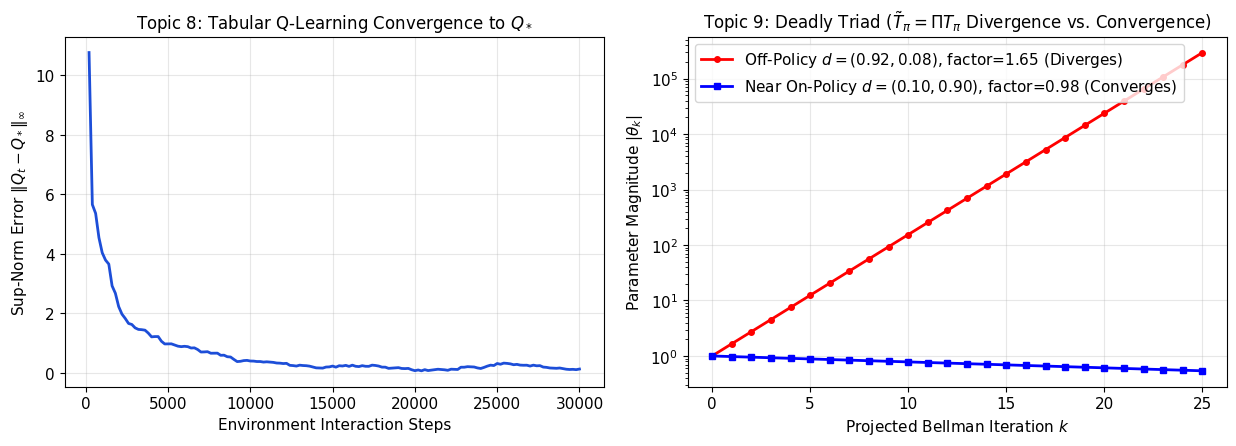

In [4]:
# Topic 8: Tabular Q-learning convergence to exact Q* on our 6-state, 3-action MDP
Q_star = R + gamma * np.einsum("san,n->sa", P, V_star)
Q_tab = np.zeros_like(R)
visit_counts = np.zeros_like(R)
q_errors = []
s = 0
num_q_steps = 30000
for step in range(1, num_q_steps + 1):
    # epsilon-greedy exploration
    if rng.random() < 0.35:
        a = rng.integers(0, M_actions)
    else:
        a = int(np.argmax(Q_tab[s]))
    s_next = int(rng.choice(N_states, p=P[s, a]))
    visit_counts[s, a] += 1
    alpha = 1.0 / (visit_counts[s, a] ** 0.65)
    td_target = R[s, a] + gamma * np.max(Q_tab[s_next])
    Q_tab[s, a] += alpha * (td_target - Q_tab[s, a])
    s = s_next
    if step % 200 == 0:
        q_errors.append(np.max(np.abs(Q_tab - Q_star)))

print(f"Topic 8 | Final Q-learning ||Q_tab - Q_*||_inf = {q_errors[-1]:.4f}")
print(f"Topic 8 | Optimal greedy policy recovered:       {np.array_equal(np.argmax(Q_tab, 1), np.argmax(Q_star, 1))}")

# Topic 9: The Deadly Triad (Tsitsiklis & Van Roy 2-state linear FA example)
# State 0 transitions to State 1; State 1 transitions to State 1 with gamma = 0.95
Phi_triad = np.array([[1.0], [2.0]])  # phi(0)=1, phi(1)=2
P_triad = np.array([[0.0, 1.0], [0.0, 1.0]])
r_triad = np.array([0.0, 0.0])        # True value V_pi = [0, 0]^T
gamma_triad = 0.95

def run_projected_bellman(d_weights, steps=25):
    D = np.diag(d_weights)
    Pi = Phi_triad @ np.linalg.inv(Phi_triad.T @ D @ Phi_triad) @ Phi_triad.T @ D
    A_mat = Pi @ (gamma_triad * P_triad)
    spec_rad = float(np.max(np.abs(np.linalg.eigvals(A_mat))))
    theta = 1.0  # initial weight theta_0 = 1 -> v_0 = Phi * theta_0
    norms = [abs(theta)]
    for _ in range(steps):
        v_curr = Phi_triad.flatten() * theta
        Tv = r_triad + gamma_triad * (P_triad @ v_curr)
        theta = float(np.linalg.inv(Phi_triad.T @ D @ Phi_triad)[0, 0] * (Phi_triad.T @ D @ Tv)[0])
        norms.append(abs(theta))
    return spec_rad, np.array(norms)

rho_off, norms_off = run_projected_bellman([0.92, 0.08])  # Skewed off-policy distribution
rho_on, norms_on = run_projected_bellman([0.10, 0.90])    # Near stationary distribution
print(f"Topic 9 | Off-policy contraction factor rho(Pi gamma P) = {rho_off:.4f} > 1 (Diverges!)")
print(f"Topic 9 | On-policy  contraction factor rho(Pi gamma P) = {rho_on:.4f} < 1 (Converges!)")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
steps_grid = np.arange(1, len(q_errors) + 1) * 200
axes[0].plot(steps_grid, q_errors, color="#1d4ed8", lw=2)
axes[0].set_title(r"Topic 8: Tabular Q-Learning Convergence to $Q_*$")
axes[0].set_xlabel("Environment Interaction Steps")
axes[0].set_ylabel(r"Sup-Norm Error $\|Q_t - Q_*\|_\infty$")

k_triad = np.arange(len(norms_off))
axes[1].semilogy(k_triad, norms_off, "r-o", markersize=4, lw=2, label=f"Off-Policy $d=(0.92, 0.08)$, factor={rho_off:.2f} (Diverges)")
axes[1].semilogy(k_triad, norms_on, "b-s", markersize=4, lw=2, label=f"Near On-Policy $d=(0.10, 0.90)$, factor={rho_on:.2f} (Converges)")
axes[1].set_title(r"Topic 9: Deadly Triad ($\tilde{T}_\pi = \Pi T_\pi$ Divergence vs. Convergence)")
axes[1].set_xlabel("Projected Bellman Iteration $k$")
axes[1].set_ylabel(r"Parameter Magnitude $|\theta_k|$")
axes[1].legend()
plt.tight_layout()
plt.show()


---
## Experiment 4: Importance Sampling Variance & Natural Policy Gradients (Topics 10 & 11)

### Mathematical Recap
- **Topic 10 (Importance Sampling)**: Under behavior policy $\mu$, the cumulative importance ratio $\rho_{0:T} = \prod_{k=0}^T \frac{\pi(a_k\mid s_k)}{\mu(a_k\mid s_k)}$ is an unbiased estimator of target-policy return ($\mathbb{E}_\mu[\rho_{0:T}G_T] = \mathbb{E}_\pi[G_T]$), but its variance grows exponentially with horizon $T$. **Weighted Importance Sampling** normalizes by $\sum_{i=1}^n \rho_{0:T}^{(i)}$, trading small finite-sample bias for bounded variance.
- **Topic 11 (Natural Policy Gradient & Trust Regions)**: To second order,
  $$D_{\mathrm{KL}}(\pi_{\boldsymbol\theta} \parallel \pi_{\boldsymbol\theta+\boldsymbol\delta}) \approx \frac{1}{2}\boldsymbol\delta^\top F(\boldsymbol\theta)\boldsymbol\delta$$
  where $F(\boldsymbol\theta)$ is the Fisher Information Matrix. Constraining $D_{\mathrm{KL}} \le \delta_{\max}$ defines a convex ellipsoid in parameter space and yields the Natural Policy Gradient $\tilde{\nabla}_{\boldsymbol\theta}J = F(\boldsymbol\theta)^{-1}\nabla_{\boldsymbol\theta}J$.


Topic 10 | Horizon T=15 Unweighted MSE: 51.64 vs Weighted IS MSE: 0.5889
Topic 11 | True KL(pi_0 || pi_delta): 3.49350532e-05 vs 0.5*d^T F d: 3.50790566e-05


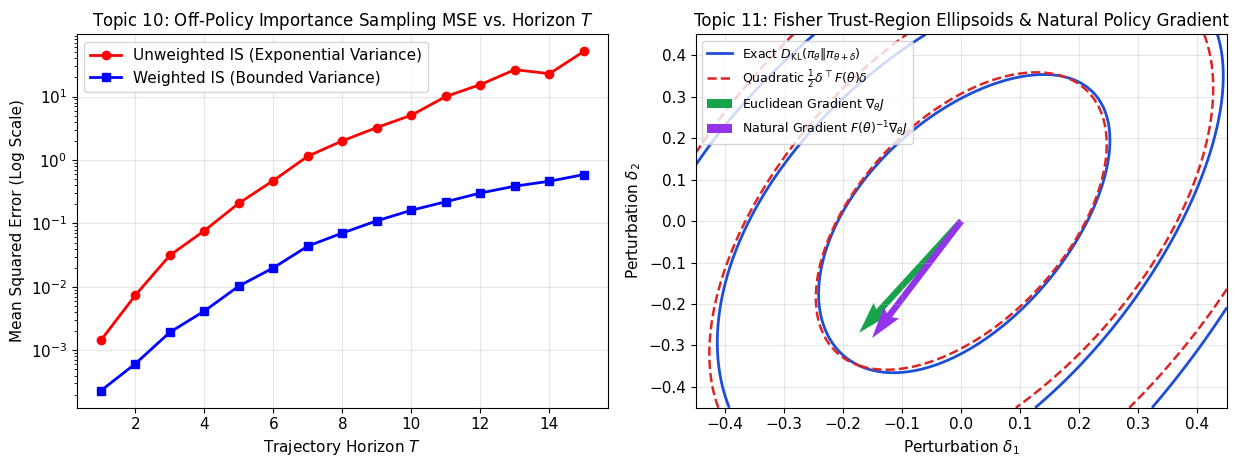

In [5]:
# Topic 10: Unweighted vs. Weighted Importance Sampling variance across trajectory horizon T
pi_prob, mu_prob = 0.78, 0.45  # target vs behavior Bernoulli action probabilities
horizons = np.arange(1, 16)
n_trajs, n_trials = 600, 150
mse_unweighted, mse_weighted = [], []

for T in horizons:
    # True expected return when each step gives reward 1 if action==1 else 0
    true_val = T * pi_prob
    acts = rng.binomial(1, mu_prob, size=(n_trials, n_trajs, T))
    returns = np.sum(acts, axis=-1)  # shape (n_trials, n_trajs)
    step_ratios = np.where(acts == 1, pi_prob / mu_prob, (1.0 - pi_prob) / (1.0 - mu_prob))
    rho = np.prod(step_ratios, axis=-1)
    est_unw = np.mean(rho * returns, axis=1)
    est_w = np.sum(rho * returns, axis=1) / (np.sum(rho, axis=1) + 1e-12)
    mse_unweighted.append(np.mean((est_unw - true_val) ** 2))
    mse_weighted.append(np.mean((est_w - true_val) ** 2))

print(f"Topic 10 | Horizon T=15 Unweighted MSE: {mse_unweighted[-1]:.2f} vs Weighted IS MSE: {mse_weighted[-1]:.4f}")

# Topic 11: Fisher Information Matrix, KL quadratic approximation & Natural Policy Gradient in PyTorch
# 2-parameter softmax policy over 3 actions (fixing logit 2 to 0 for 2D visualization)
theta_0 = torch.tensor([1.1, -0.6], dtype=torch.float64)
reward_vec = torch.tensor([1.5, 0.2, 3.0], dtype=torch.float64)

def policy_probs(th):
    full_logits = torch.cat([th, torch.zeros(1, dtype=torch.float64)])
    return torch.softmax(full_logits, dim=0)

pi_0 = policy_probs(theta_0)
# Score vectors grad_theta log pi(a | theta_0) for each of the 3 actions
scores_2d = torch.zeros((3, 2), dtype=torch.float64)
for a in range(3):
    th_var = theta_0.clone().detach().requires_grad_(True)
    log_pa = torch.log(policy_probs(th_var)[a])
    log_pa.backward()
    scores_2d[a] = th_var.grad

F_mat = torch.einsum("a,ai,aj->ij", pi_0, scores_2d, scores_2d)
grad_J = torch.einsum("a,a,ai->i", pi_0, reward_vec, scores_2d)
nat_grad_J = torch.linalg.solve(F_mat, grad_J)

delta_test = torch.tensor([0.01, -0.015], dtype=torch.float64)
pi_pert = policy_probs(theta_0 + delta_test)
kl_true = torch.sum(pi_0 * (torch.log(pi_0) - torch.log(pi_pert))).item()
kl_taylor = 0.5 * (delta_test @ F_mat @ delta_test).item()
print(f"Topic 11 | True KL(pi_0 || pi_delta): {kl_true:.8e} vs 0.5*d^T F d: {kl_taylor:.8e}")

# Grid for 2D visualization of exact KL contours vs Fisher ellipsoid
g1 = np.linspace(-0.45, 0.45, 100)
g2 = np.linspace(-0.45, 0.45, 100)
G1, G2 = np.meshgrid(g1, g2)
KL_grid = np.zeros_like(G1)
Quad_grid = np.zeros_like(G1)
F_np = F_mat.numpy()
for i in range(100):
    for j in range(100):
        d_vec = np.array([G1[i, j], G2[i, j]])
        p_new = policy_probs(theta_0 + torch.tensor(d_vec, dtype=torch.float64)).numpy()
        p_old = pi_0.numpy()
        KL_grid[i, j] = np.sum(p_old * (np.log(p_old) - np.log(p_new)))
        Quad_grid[i, j] = 0.5 * (d_vec @ F_np @ d_vec)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
axes[0].semilogy(horizons, mse_unweighted, "r-o", lw=2, label="Unweighted IS (Exponential Variance)")
axes[0].semilogy(horizons, mse_weighted, "b-s", lw=2, label="Weighted IS (Bounded Variance)")
axes[0].set_title("Topic 10: Off-Policy Importance Sampling MSE vs. Horizon $T$")
axes[0].set_xlabel("Trajectory Horizon $T$")
axes[0].set_ylabel("Mean Squared Error (Log Scale)")
axes[0].legend()

cs1 = axes[1].contour(G1, G2, KL_grid, levels=[0.005, 0.015, 0.03], colors="#1d4ed8", linewidths=2)
cs2 = axes[1].contour(G1, G2, Quad_grid, levels=[0.005, 0.015, 0.03], colors="#dc2626", linestyles="dashed", linewidths=1.8)
axes[1].plot([], [], color="#1d4ed8", lw=2, label=r"Exact $D_{\mathrm{KL}}(\pi_\theta \| \pi_{\theta+\delta})$")
axes[1].plot([], [], color="#dc2626", ls="--", lw=1.8, label=r"Quadratic $\frac{1}{2}\delta^\top F(\theta)\delta$")

g_euc = grad_J.numpy() / np.linalg.norm(grad_J.numpy()) * 0.32
g_nat = nat_grad_J.numpy() / np.linalg.norm(nat_grad_J.numpy()) * 0.32
axes[1].quiver(0, 0, g_euc[0], g_euc[1], angles="xy", scale_units="xy", scale=1, color="#16a34a", width=0.012, label=r"Euclidean Gradient $\nabla_\theta J$")
axes[1].quiver(0, 0, g_nat[0], g_nat[1], angles="xy", scale_units="xy", scale=1, color="#9333ea", width=0.012, label=r"Natural Gradient $F(\theta)^{-1}\nabla_\theta J$")
axes[1].set_title("Topic 11: Fisher Trust-Region Ellipsoids & Natural Policy Gradient")
axes[1].set_xlabel(r"Perturbation $\delta_1$")
axes[1].set_ylabel(r"Perturbation $\delta_2$")
axes[1].legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()
